In [42]:
import subprocess
from pathlib import Path

GITHUB_USERNAME = "Priyasahaana"
GITHUB_EMAIL = "2026aj05309@wilp.bits-pilani.ac.in"

REPO_URL = (
    "https://github.com/Priyasahaana/"
    "2026AJ05309_ML_Assignment2_ShopSense_Online_Purchase_Intention.git"
)

REPO_DIR = Path("/content/2026AJ05309_ShopSense_Online_Purchase_Intention")

print("GitHub repository:", REPO_URL)
print("Local working directory:", REPO_DIR)

GitHub repository: https://github.com/Priyasahaana/2026AJ05309_ML_Assignment2_ShopSense_Online_Purchase_Intention.git
Local working directory: /content/2026AJ05309_ShopSense_Online_Purchase_Intention


In [43]:
from google.colab import userdata
GITHUB_TOKEN = userdata.get("GITHUB_TOKEN")
if not GITHUB_TOKEN:
    raise ValueError(
        "GITHUB_TOKEN not found. Check Colab Secrets and notebook access."
    )
subprocess.run(
    ["git", "config", "--global", "credential.helper", "store"],
    check=True
)
credential_text = (
    "protocol=https\n"
    "host=github.com\n"
    f"username={GITHUB_USERNAME}\n"
    f"password={GITHUB_TOKEN}\n\n"
)
subprocess.run(
    ["git", "credential", "approve"],
    input=credential_text,
    text=True,
    check=True
)
del GITHUB_TOKEN
print("GitHub authentication configured for this Colab runtime.")

GitHub authentication configured for this Colab runtime.


In [44]:
if REPO_DIR.exists():
    print("Repository folder already exists. Reusing it.")
else:
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True
    )
    print("Repository cloned successfully.")
subprocess.run(
    ["git", "-C", str(REPO_DIR), "branch", "-M", "main"],
    check=True
)
subprocess.run(
    ["git", "-C", str(REPO_DIR), "config", "user.name", GITHUB_USERNAME],
    check=True
)
subprocess.run(
    ["git", "-C", str(REPO_DIR), "config", "user.email", GITHUB_EMAIL],
    check=True
)
print("Main branch and commit identity configured.")

Repository folder already exists. Reusing it.
Main branch and commit identity configured.


In [45]:
subprocess.run(
    ["git", "-C", str(REPO_DIR), "status"],
    check=True
)
print("\nRemote repository:")
subprocess.run(
    ["git", "-C", str(REPO_DIR), "remote", "-v"],
    check=True
)


Remote repository:


CompletedProcess(args=['git', '-C', '/content/2026AJ05309_ShopSense_Online_Purchase_Intention', 'remote', '-v'], returncode=0)

## 1. Environment setup
Install the libraries used for data loading, analysis, modelling, evaluation, and saving model artifacts. We do not force a protobuf version: this notebook does not need TensorFlow, and Streamlit is installed separately for deployment.

In [46]:
%pip install -q ucimlrepo scikit-learn pandas numpy matplotlib seaborn joblib scipy

## 2. Imports, reproducibility, and project folders

In [47]:
from pathlib import Path
import json, sys, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)

RANDOM_STATE = 42
TEST_SIZE = 0.20
PROJECT_DIR = Path("ShopSense")
MODEL_DIR = PROJECT_DIR / "model"
ASSET_DIR = PROJECT_DIR / "assets"
for folder in [PROJECT_DIR, MODEL_DIR, ASSET_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__, "| NumPy:", np.__version__, "| Scikit-learn:", sklearn.__version__)
print("Project folder:", PROJECT_DIR.resolve())

Python: 3.13.18
Pandas: 2.2.3 | NumPy: 2.4.6 | Scikit-learn: 1.6.1
Project folder: /content/ShopSense


## 3. Load the UCI dataset
The preferred route uses `ucimlrepo` and UCI dataset ID **468**. If the environment cannot connect to UCI, use a local CSV named `online_shoppers_intention.csv`.

In [48]:
LOCAL_DATA_PATH = Path("online_shoppers_intention.csv")

if LOCAL_DATA_PATH.exists():
    raw_df = pd.read_csv(LOCAL_DATA_PATH)
    print("Loaded local CSV:", LOCAL_DATA_PATH.resolve())
else:
    try:
        from ucimlrepo import fetch_ucirepo
        uci_dataset = fetch_ucirepo(id=468)
        raw_df = pd.concat(
            [uci_dataset.data.features.copy(), uci_dataset.data.targets.copy()],
            axis=1
        )
        print("Downloaded UCI dataset ID 468.")
    except Exception as exc:
        raise RuntimeError(
            "UCI download failed. Download the Online Shoppers Purchasing Intention "
            "CSV, save it beside this notebook as 'online_shoppers_intention.csv', "
            f"and rerun this cell. Original error: {exc}"
        )

raw_df.columns = [str(c).strip() for c in raw_df.columns]
if "Revenue" not in raw_df.columns:
    raise ValueError(f"Expected target column 'Revenue'. Columns found: {raw_df.columns.tolist()}")

df = raw_df.copy()
if pd.api.types.is_bool_dtype(df["Revenue"]):
    df["Revenue"] = df["Revenue"].astype(int)
else:
    target_map = {True: 1, False: 0, "true": 1, "false": 0, "1": 1, "0": 0, 1: 1, 0: 0}
    converted = df["Revenue"].map(
        lambda v: target_map.get(v, target_map.get(str(v).strip().lower(), np.nan))
    )
    if converted.isna().any():
        raise ValueError(f"Unrecognized Revenue values: {df['Revenue'].dropna().unique()[:10]}")
    df["Revenue"] = converted.astype(int)

print("Dataset shape:", df.shape)
display(df.head())

Downloaded UCI dataset ID 468.
Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,0


## 4. Verify dataset size and assignment minimums

In [49]:
target_column = "Revenue"
feature_columns = [c for c in df.columns if c != target_column]
print("Instances:", len(df))
print("Input features:", len(feature_columns))
print("Target classes:", sorted(df[target_column].unique().tolist()))
assert len(df) >= 500, "Dataset does not meet the 500-instance minimum."
assert len(feature_columns) >= 12, "Dataset does not meet the 12-feature minimum."
assert set(df[target_column].unique()).issubset({0, 1})
print("Assignment minimums satisfied.")

Instances: 12330
Input features: 17
Target classes: [0, 1]
Assignment minimums satisfied.


In [50]:
from google.colab import drive
drive.mount('/content/drive')
import subprocess
NOTEBOOK_NAME = "2026AJ05309_MACHINE_LEARNING_AIMLZG565_Assignment2.ipynb"
result = subprocess.run(
    ["find", "/content/drive/MyDrive", "-type", "f", "-name", NOTEBOOK_NAME],
    capture_output=True,
    text=True,
    check=True
)
NOTEBOOK_PATH = Path(result.stdout.strip().splitlines()[0]) if result.stdout.strip() else None
if NOTEBOOK_PATH is None:
    print("Notebook not found. Check its name and Google Drive location.")
else:
    print("Notebook found:", NOTEBOOK_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Notebook found: /content/drive/MyDrive/Colab Notebooks/2026AJ05309_MACHINE_LEARNING_AIMLZG565_Assignment2.ipynb


In [51]:
import shutil
import subprocess
from pathlib import Path
NOTEBOOK_PATH = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "2026AJ05309_MACHINE_LEARNING_AIMLZG565_Assignment2.ipynb"
)
REPO_NOTEBOOK_PATH = REPO_DIR / NOTEBOOK_PATH.name
if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError("Notebook not found in Google Drive.")
shutil.copy2(NOTEBOOK_PATH, REPO_NOTEBOOK_PATH)
gitignore_text = """
__pycache__/
.ipynb_checkpoints/
*.pyc
ShopSense_project.zip
.DS_Store
"""
(REPO_DIR / ".gitignore").write_text(
    gitignore_text.strip() + "\n",
    encoding="utf-8"
)
subprocess.run(
    ["git", "-C", str(REPO_DIR), "add", ".gitignore", NOTEBOOK_PATH.name],
    check=True
)
subprocess.run(
    ["git", "-C", str(REPO_DIR), "status", "--short"],
    check=True
)
subprocess.run(
    [
        "git", "-C", str(REPO_DIR),
        "commit", "-m",
        "Initial commit: ShopSense notebook and project setup"
    ],
    check=True
)
subprocess.run(
    ["git", "-C", str(REPO_DIR), "push", "-u", "origin", "main"],
    check=True
)
print("\nFirst commit pushed successfully!")
subprocess.run(
    ["git", "-C", str(REPO_DIR), "log", "-1", "--oneline"],
    check=True
)
print("\nGitHub repository:")
print(REPO_URL)


First commit pushed successfully!

GitHub repository:
https://github.com/Priyasahaana/2026AJ05309_ML_Assignment2_ShopSense_Online_Purchase_Intention.git


## 5. Data quality and target balance

In [52]:
quality_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})
display(quality_summary)
print("Exact duplicate rows:", int(df.duplicated().sum()))
display(df["Revenue"].value_counts().rename(index={0:"No purchase", 1:"Purchase"}).to_frame("sessions"))
display((df["Revenue"].value_counts(normalize=True)*100).round(2).rename(index={0:"No purchase",1:"Purchase"}).to_frame("percent"))

,missing_count,missing_percent,unique_values
Administrative,0,0.0,27
Administrative_Duration,0,0.0,3335
Informational,0,0.0,17
Informational_Duration,0,0.0,1258
ProductRelated,0,0.0,311
ProductRelated_Duration,0,0.0,9551
BounceRates,0,0.0,1872
ExitRates,0,0.0,4777
PageValues,0,0.0,2704
SpecialDay,0,0.0,6


Exact duplicate rows: 125


,sessions
Revenue,
No purchase,10422
Purchase,1908


,percent
Revenue,
No purchase,84.53
Purchase,15.47


## 6. Define numerical and categorical features
Seven variables are categorical even when represented by numeric category codes. Do not include `Revenue` in either feature list.

In [53]:
categorical_features = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]
numerical_features = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay"
]

missing_columns = sorted(set(numerical_features + categorical_features + ["Revenue"]) - set(df.columns))
unassigned_columns = sorted(set(feature_columns) - set(numerical_features + categorical_features))
print("Numerical:", len(numerical_features), numerical_features)
print("Categorical:", len(categorical_features), categorical_features)
print("Missing expected columns:", missing_columns)
print("Unassigned input columns:", unassigned_columns)
assert not missing_columns, f"Missing expected columns: {missing_columns}"
assert not unassigned_columns, f"Unassigned columns: {unassigned_columns}"
assert "Revenue" not in numerical_features + categorical_features

Numerical: 10 ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Categorical: 7 ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
Missing expected columns: []
Unassigned input columns: []


## 7. EDA — purchase outcome distribution

/tmp/ipykernel_1236/737141056.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=target_counts.index, y=target_counts.values, ax=ax, palette="Set2")


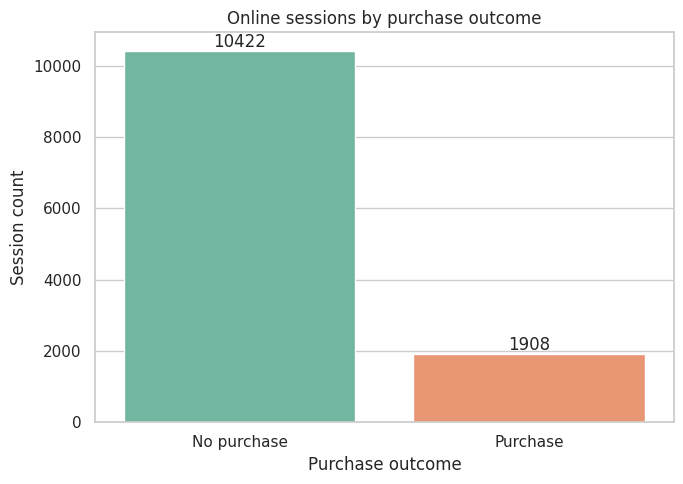

In [54]:
fig, ax = plt.subplots(figsize=(7, 5))
target_counts = df["Revenue"].map({0:"No purchase", 1:"Purchase"}).value_counts()
sns.barplot(x=target_counts.index, y=target_counts.values, ax=ax, palette="Set2")
ax.set(title="Online sessions by purchase outcome", xlabel="Purchase outcome", ylabel="Session count")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.tight_layout()
plt.savefig(ASSET_DIR / "target_distribution.png", dpi=220, bbox_inches="tight")
plt.show()

## 8. EDA — numerical feature distributions

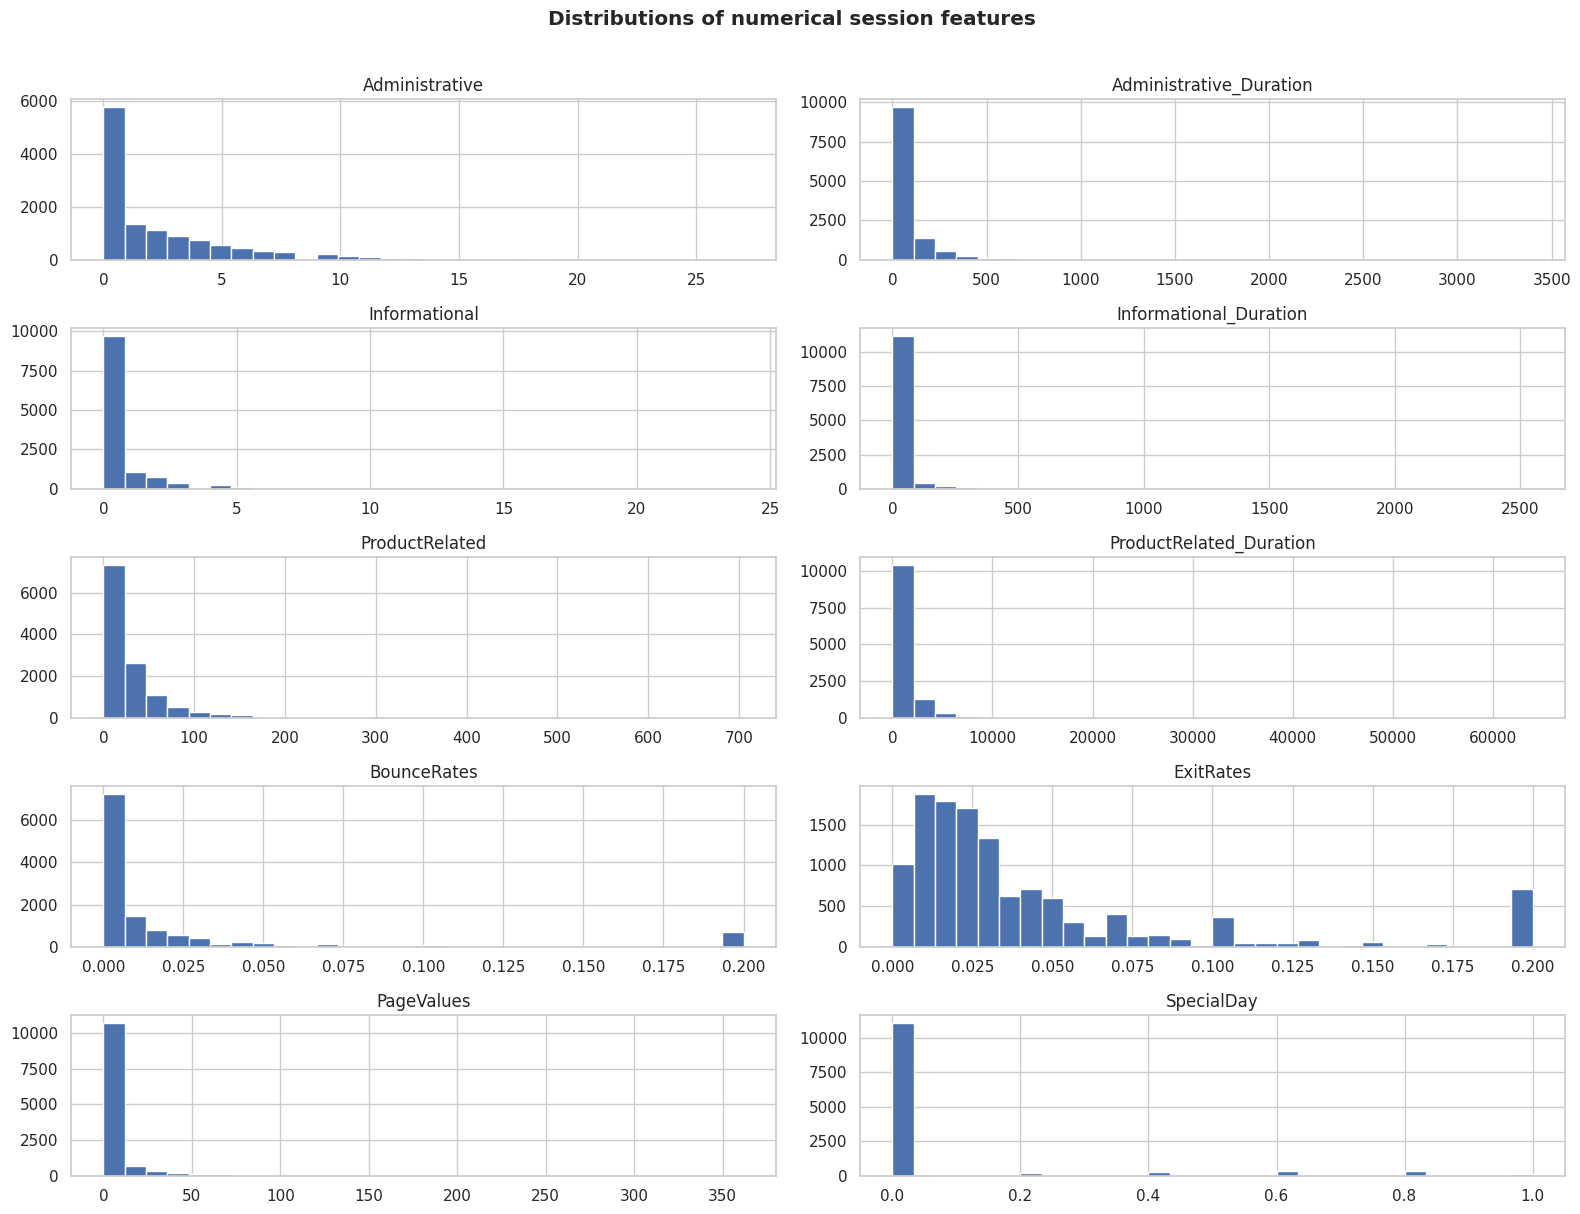

In [55]:
df[numerical_features].hist(figsize=(16, 12), bins=30, edgecolor="white", layout=(5, 2))
plt.suptitle("Distributions of numerical session features", y=1.01, fontweight="bold")
plt.tight_layout()
plt.savefig(ASSET_DIR / "numerical_distributions.png", dpi=220, bbox_inches="tight")
plt.show()

## 9. EDA — numerical correlation

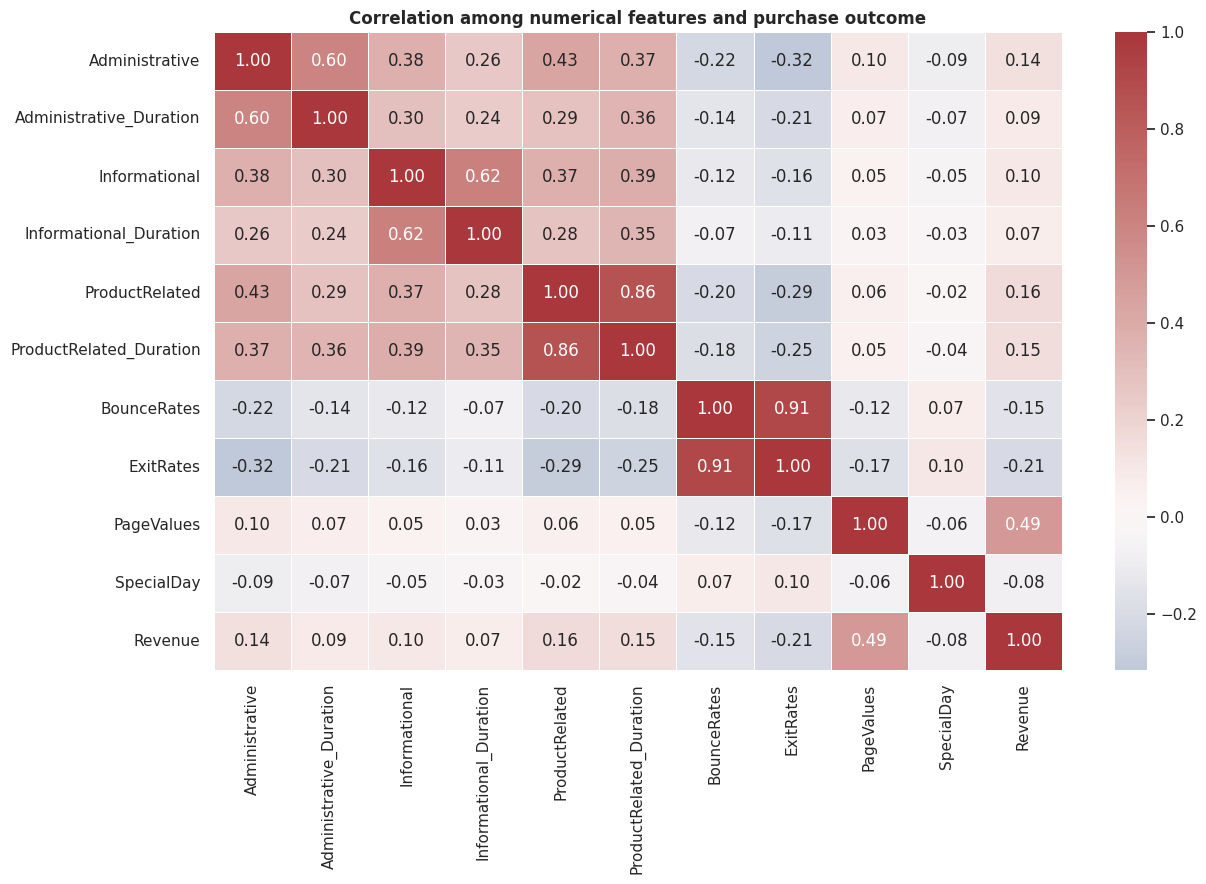

In [56]:
corr_matrix = df[numerical_features + ["Revenue"]].corr(numeric_only=True)
plt.figure(figsize=(13, 9))
sns.heatmap(corr_matrix, cmap="vlag", center=0, annot=True, fmt=".2f", linewidths=0.4)
plt.title("Correlation among numerical features and purchase outcome", fontweight="bold")
plt.tight_layout()
plt.savefig(ASSET_DIR / "correlation_heatmap.png", dpi=220, bbox_inches="tight")
plt.show()

## 10. EDA — categorical purchase outcome plots
A dynamic subplot layout creates one panel per feature and removes unused positions. This plotting list is separate from the preprocessing feature list.

In [ ]:
categorical_plot_features = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]
n_features = len(categorical_plot_features)
n_cols = 2
n_rows = int(np.ceil(n_features / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5 * n_rows))
axes = np.asarray(axes).reshape(-1)

for i, feature in enumerate(categorical_plot_features):
    sns.countplot(data=df, x=feature, hue="Revenue", ax=axes[i], palette="Set2")
    axes[i].set_title(f"{feature} vs Purchase Outcome", fontweight="bold")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Session count")
    axes[i].tick_params(axis="x", rotation=35)
    axes[i].legend(title="Revenue", labels=["No purchase", "Purchase"])

for j in range(n_features, len(axes)):
    fig.delaxes(axes[j])
fig.suptitle("Purchase outcome across categorical session features", y=1.01, fontweight="bold")
plt.tight_layout()
plt.savefig(ASSET_DIR / "categorical_analysis.png", dpi=220, bbox_inches="tight")
plt.show()

In [ ]:
import shutil
REPO_NOTEBOOK_PATH = REPO_DIR / NOTEBOOK_PATH.name
if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError("Notebook not found in Google Drive.")
shutil.copy2(NOTEBOOK_PATH, REPO_NOTEBOOK_PATH)
print("Updated notebook copied to GitHub working folder.")
subprocess.run(["git", "-C", str(REPO_DIR), "add", NOTEBOOK_PATH.name], check=True)
print("\nFiles staged:")
staged_files = subprocess.run(["git", "-C", str(REPO_DIR), "diff", "--cached", "--name-only"], capture_output=True, text=True, check=True)
print(staged_files.stdout if staged_files.stdout.strip() else "No files staged.")
if staged_files.stdout.strip():
    subprocess.run(["git", "-C", str(REPO_DIR), "commit", "-m", "Add data quality checks and exploratory data analysis"], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "push", "origin", "main"], check=True)
    print("\nSecond milestone committed and pushed successfully!")
else:
    print("\nNo new changes detected. Nothing to commit or push.")
print("\nLatest commit:")
latest_commit = subprocess.run(["git", "-C", str(REPO_DIR), "log", "-1", "--oneline"], capture_output=True, text=True, check=True)
print(latest_commit.stdout)

## 11. Create one stratified train/test split
The split occurs before fitting imputers, scalers, or encoders. All five models share this exact split.

In [ ]:
X = df[numerical_features + categorical_features].copy()
y = df["Revenue"].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Train class proportions:")
display(y_train.value_counts(normalize=True).to_frame("proportion"))
print("Test class proportions:")
display(y_test.value_counts(normalize=True).to_frame("proportion"))
assert list(X_train.columns) == list(X_test.columns)

## 12. Define preprocessing pipelines
Numerical features: median imputation and standardization. Categorical features: most-frequent imputation and one-hot encoding. The preprocessing is embedded in each model pipeline, preventing test-data leakage.

In [ ]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numerical", numeric_transformer, numerical_features),
    ("categorical", categorical_transformer, categorical_features)
], sparse_threshold=0)
print("Preprocessing pipeline created successfully.")

## 13. Define the five required classifiers

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=15, weights="distance"),
    "Gaussian Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(kernel="rbf", C=1.0, probability=True, random_state=RANDOM_STATE)
}
for name in models:
    print("-", name)

In [ ]:
import shutil
REPO_NOTEBOOK_PATH = REPO_DIR / NOTEBOOK_PATH.name
if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError("Notebook not found in Google Drive.")
shutil.copy2(NOTEBOOK_PATH, REPO_NOTEBOOK_PATH)
print("Updated notebook copied to GitHub working folder.")
subprocess.run(["git","-C",str(REPO_DIR),"add",NOTEBOOK_PATH.name],check=True)
staged_files = subprocess.run(["git","-C",str(REPO_DIR),"diff","--cached","--name-only"],capture_output=True,text=True,check=True)
print("\nFiles staged:")
print(staged_files.stdout if staged_files.stdout.strip() else "No files staged.")
if staged_files.stdout.strip():
    subprocess.run(["git","-C",str(REPO_DIR),"commit","-m","Add train-test split, preprocessing and classifier definitions"],check=True)
    subprocess.run(["git","-C",str(REPO_DIR),"push","origin","main"],check=True)
    print("\nThird milestone committed and pushed successfully!")
else:
    print("\nNo new changes detected. Nothing to commit or push.")
print("\nLatest commit:")
latest_commit = subprocess.run(["git","-C",str(REPO_DIR),"log","-1","--oneline"],capture_output=True,text=True,check=True)
print(latest_commit.stdout)

## 14. Train and evaluate all models
ROC-AUC is calculated from positive-class probabilities. Precision, recall, and F1 use `1` (purchase) as the positive class. MCC complements accuracy when classes are imbalanced.

In [ ]:
trained_pipelines = {}
predictions = {}
probabilities = {}
result_rows = []

for model_name, classifier in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    result_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })
    trained_pipelines[model_name] = pipeline
    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

results_df = pd.DataFrame(result_rows).set_index("Model").sort_values("AUC", ascending=False)
display(results_df.style.format("{:.4f}"))

## 15. Compare model metrics visually

In [ ]:
metric_columns = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
ax = results_df[metric_columns].plot(kind="bar", figsize=(15, 7), ylim=(-1, 1.05), width=0.82)
ax.set_title("Five-classifier comparison across evaluation metrics", fontweight="bold")
ax.set_xlabel("Classifier")
ax.set_ylabel("Metric score")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(ASSET_DIR / "model_metric_comparison.png", dpi=220, bbox_inches="tight")
plt.show()

## 16. Confusion matrices and classification reports

In [ ]:
for model_name, y_pred in predictions.items():
    print("=" * 72)
    print(model_name)
    print("=" * 72)
    print(classification_report(
        y_test, y_pred, labels=[0, 1],
        target_names=["No purchase", "Purchase"], zero_division=0
    ))
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(cm, display_labels=["No purchase", "Purchase"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(f"{model_name} — Confusion Matrix", fontweight="bold")
    plt.tight_layout()
    safe_name = model_name.lower().replace(" ", "_")
    plt.savefig(ASSET_DIR / f"confusion_matrix_{safe_name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 17. ROC curves

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))
for model_name, y_prob in probabilities.items():
    RocCurveDisplay.from_predictions(
        y_test, y_prob,
        name=f"{model_name} (AUC={roc_auc_score(y_test, y_prob):.3f})",
        ax=ax
    )
ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("ROC curves — five classifiers", fontweight="bold")
plt.tight_layout()
plt.savefig(ASSET_DIR / "roc_curves.png", dpi=220, bbox_inches="tight")
plt.show()

## 18. Interpret results and identify the overall winner

The performance of all five classification models is compared using six evaluation metrics: Accuracy, ROC-AUC, Precision, Recall, F1 Score, and Matthews Correlation Coefficient (MCC).

The overall winner is identified using the average rank across all six metrics, giving equal importance to each metric rather than relying on a single performance measure. The final interpretation also considers the trade-off between false positives and false negatives.

Review the comparison table and add observations about the strengths and limitations of each model. Explain why the selected model is suitable for predicting online purchase intention.

In [ ]:
metric_columns = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
model_ranks = results_df[metric_columns].rank(ascending=False, method="average")
results_df["Average Rank"] = model_ranks.mean(axis=1)
overall_winner = results_df["Average Rank"].idxmin()

print("Overall winner based on all six metrics:", overall_winner)
display(results_df.round(4))

In [ ]:
import shutil
REPO_NOTEBOOK_PATH = REPO_DIR / NOTEBOOK_PATH.name
if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError("Notebook not found in Google Drive.")
shutil.copy2(NOTEBOOK_PATH, REPO_NOTEBOOK_PATH)
print("Updated notebook copied to GitHub working folder.")
subprocess.run(["git","-C",str(REPO_DIR),"add",NOTEBOOK_PATH.name],check=True)
staged_files = subprocess.run(["git","-C",str(REPO_DIR),"diff","--cached","--name-only"],capture_output=True,text=True,check=True)
print("\nFiles staged:")
print(staged_files.stdout if staged_files.stdout.strip() else "No files staged.")
if staged_files.stdout.strip():
    subprocess.run(["git","-C",str(REPO_DIR),"commit","-m","Train and evaluate five classification models"],check=True)
    subprocess.run(["git","-C",str(REPO_DIR),"push","origin","main"],check=True)
    print("\nFourth milestone committed and pushed successfully!")
else:
    print("\nNo new changes detected. Nothing to commit or push.")
print("\nLatest commit:")
latest_commit = subprocess.run(["git","-C",str(REPO_DIR),"log","-1","--oneline"],capture_output=True,text=True,check=True)
print(latest_commit.stdout)

## 19. Save model pipelines, metrics, test data, and metadata

In [ ]:
for model_name, fitted_pipeline in trained_pipelines.items():
    filename = model_name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(fitted_pipeline, MODEL_DIR / filename)

results_df.to_csv(PROJECT_DIR / "model_comparison.csv")
test_data = X_test.copy()
test_data["Revenue"] = y_test.values
test_data.to_csv(PROJECT_DIR / "test_data.csv", index=False)

metadata = {
    "project": "ShopSense — Online Purchase Intention Analytics",
    "dataset": "UCI Online Shoppers Purchasing Intention",
    "uci_dataset_id": 468,
    "target_column": "Revenue",
    "target_mapping": {"0": "No purchase", "1": "Purchase"},
    "numerical_features": numerical_features,
    "categorical_features": categorical_features,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "scikit_learn_version": sklearn.__version__,
    "provisional_winner_by_auc": overall_winner
}
(PROJECT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("Saved model artifacts:", len(list(MODEL_DIR.glob("*.joblib"))))
print("Test data shape:", test_data.shape)

In [ ]:
print("Checking saved project artifacts...")
print("\nModel files:")
for model_file in sorted(MODEL_DIR.glob("*.joblib")):
    print(model_file.name, "-", round(model_file.stat().st_size / 1024, 2), "KB")
print("\nTest data exists:", (PROJECT_DIR / "test_data.csv").exists())
print("Metadata exists:", (PROJECT_DIR / "metadata.json").exists())
print("\nTotal saved models:", len(list(MODEL_DIR.glob("*.joblib"))))

In [ ]:
import shutil
REPO_NOTEBOOK_PATH = REPO_DIR / NOTEBOOK_PATH.name
if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError("Notebook not found in Google Drive.")
shutil.copy2(NOTEBOOK_PATH, REPO_NOTEBOOK_PATH)
print("Updated notebook copied to GitHub working folder.")
subprocess.run(["git","-C",str(REPO_DIR),"add",NOTEBOOK_PATH.name],check=True)
staged_files = subprocess.run(["git","-C",str(REPO_DIR),"diff","--cached","--name-only"],capture_output=True,text=True,check=True)
print("\nFiles staged:")
print(staged_files.stdout if staged_files.stdout.strip() else "No files staged.")
if staged_files.stdout.strip():
    subprocess.run(["git","-C",str(REPO_DIR),"commit","-m","Save trained models and test data artifacts"],check=True)
    subprocess.run(["git","-C",str(REPO_DIR),"push","origin","main"],check=True)
    print("\nFifth milestone committed and pushed successfully!")
else:
    print("\nNo new changes detected. Nothing to commit or push.")
print("\nLatest commit:")
latest_commit = subprocess.run(["git","-C",str(REPO_DIR),"log","-1","--oneline"],capture_output=True,text=True,check=True)
print(latest_commit.stdout)

## 20. Generate the Streamlit application (`app.py`)
The app supports labelled CSV upload, model selection, all six metrics, a confusion matrix, and a classification report. It loads saved pipelines and does not retrain on uploaded data.

In [ ]:
app_source = '\nfrom pathlib import Path\nimport joblib\nimport numpy as np\nimport pandas as pd\nimport streamlit as st\nimport matplotlib.pyplot as plt\nfrom sklearn.metrics import (\n    accuracy_score, roc_auc_score, precision_score, recall_score,\n    f1_score, matthews_corrcoef, confusion_matrix,\n    ConfusionMatrixDisplay, classification_report\n)\n\nBASE_DIR = Path(__file__).resolve().parent\nMODEL_DIR = BASE_DIR / "model"\nTARGET = "Revenue"\nMODEL_FILES = {\n    "Logistic Regression": "logistic_regression.joblib",\n    "Decision Tree": "decision_tree.joblib",\n    "K-Nearest Neighbors": "k-nearest_neighbors.joblib",\n    "Gaussian Naive Bayes": "gaussian_naive_bayes.joblib",\n    "Support Vector Machine": "support_vector_machine.joblib",\n}\n\nst.set_page_config(page_title="ShopSense | Purchase Intelligence", page_icon="🛍️", layout="wide")\nst.markdown(\n    "<style>.stApp{background:linear-gradient(180deg,#f7f9fc 0%,#fff 45%);}"\n    ".main-title{font-size:2.45rem;font-weight:800;color:#172554;margin-bottom:0;}"\n    ".subtitle{color:#475569;font-size:1.02rem;margin-top:.2rem;}"\n    "div[data-testid=\'stMetric\']{background:#fff;border:1px solid #e2e8f0;"\n    "padding:14px 16px;border-radius:12px;}</style>",\n    unsafe_allow_html=True\n)\nst.markdown("<div class=\'main-title\'>ShopSense</div>", unsafe_allow_html=True)\nst.markdown(\n    "<div class=\'subtitle\'>Online Purchase Intention Analytics · "\n    "Compare five classifiers on held-out sessions</div>",\n    unsafe_allow_html=True\n)\nst.write("")\nst.info(\n    "Upload a labelled test CSV containing the session features and Revenue target. "\n    "The selected saved model evaluates the file; no model is retrained."\n)\n\n@st.cache_resource\ndef load_model(path):\n    return joblib.load(path)\n\nwith st.sidebar:\n    st.header("Evaluation controls")\n    selected_model = st.selectbox("Choose classifier", list(MODEL_FILES.keys()))\n    uploaded_file = st.file_uploader("Upload labelled test data (CSV)", type=["csv"])\n    st.caption("Expected target: Revenue (True/False or 1/0).")\n    st.divider()\n    st.caption("Saved pipelines are loaded from the repository\'s model/ folder.")\n\nif uploaded_file is None:\n    st.subheader("How to use this dashboard")\n    st.markdown(\n        "1. Select a classifier in the sidebar.\\n"\n        "2. Upload `test_data.csv` from the project folder.\\n"\n        "3. Review the six metrics, confusion matrix, and class-wise report."\n    )\n    st.caption("The repository includes a sample held-out test file for evaluation.")\n    st.stop()\n\ntry:\n    test_df = pd.read_csv(uploaded_file)\n    if TARGET not in test_df.columns:\n        raise ValueError("The uploaded CSV must include the target column Revenue.")\n\n    y_raw = test_df[TARGET]\n    if pd.api.types.is_bool_dtype(y_raw):\n        y_true = y_raw.astype(int)\n    else:\n        target_map = {True: 1, False: 0, "true": 1, "false": 0, "1": 1, "0": 0, 1: 1, 0: 0}\n        y_true = y_raw.map(\n            lambda v: target_map.get(v, target_map.get(str(v).strip().lower(), np.nan))\n        )\n        if y_true.isna().any():\n            raise ValueError("Revenue values must be True/False or 1/0.")\n        y_true = y_true.astype(int)\n\n    X_uploaded = test_df.drop(columns=[TARGET])\n    model_path = MODEL_DIR / MODEL_FILES[selected_model]\n    if not model_path.exists():\n        raise FileNotFoundError(f"Saved model not found: {model_path.name}")\n\n    pipeline = load_model(str(model_path))\n    expected_features = list(pipeline.feature_names_in_)\n    missing = sorted(set(expected_features) - set(X_uploaded.columns))\n    extra = sorted(set(X_uploaded.columns) - set(expected_features))\n    if missing:\n        raise ValueError(f"Missing required input columns: {missing}")\n    if extra:\n        st.warning(f"Extra columns will be ignored: {extra}")\n    X_uploaded = X_uploaded[expected_features]\n\n    y_pred = pipeline.predict(X_uploaded)\n    y_score = pipeline.predict_proba(X_uploaded)[:, 1]\n    auc_value = roc_auc_score(y_true, y_score) if len(np.unique(y_true)) == 2 else np.nan\n    if np.isnan(auc_value):\n        st.warning("ROC-AUC is undefined because the uploaded target contains only one class.")\n\n    metrics = {\n        "Accuracy": accuracy_score(y_true, y_pred),\n        "ROC-AUC": auc_value,\n        "Precision": precision_score(y_true, y_pred, zero_division=0),\n        "Recall": recall_score(y_true, y_pred, zero_division=0),\n        "F1-score": f1_score(y_true, y_pred, zero_division=0),\n        "MCC": matthews_corrcoef(y_true, y_pred)\n    }\n\n    st.subheader(f"Results · {selected_model}")\n    st.caption(f"Evaluated {len(test_df):,} labelled sessions.")\n    metric_cols = st.columns(3)\n    for i, (name, value) in enumerate(metrics.items()):\n        with metric_cols[i % 3]:\n            st.metric(name, "N/A" if pd.isna(value) else f"{value:.4f}")\n\n    left, right = st.columns(2)\n    with left:\n        st.markdown("### Confusion matrix")\n        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])\n        fig, ax = plt.subplots(figsize=(5.4, 4.2))\n        ConfusionMatrixDisplay(cm, display_labels=["No purchase", "Purchase"]).plot(\n            ax=ax, cmap="Blues", colorbar=False, values_format="d"\n        )\n        ax.set_title(selected_model)\n        st.pyplot(fig)\n        plt.close(fig)\n\n    with right:\n        st.markdown("### Classification report")\n        report = classification_report(\n            y_true, y_pred, labels=[0, 1],\n            target_names=["No purchase", "Purchase"],\n            output_dict=True, zero_division=0\n        )\n        st.dataframe(pd.DataFrame(report).T.round(4), use_container_width=True)\n\n    with st.expander("Preview uploaded test data"):\n        st.dataframe(test_df.head(20), use_container_width=True)\n\nexcept Exception as exc:\n    st.error(f"Evaluation could not be completed: {exc}")\n    st.caption("Check that the CSV has the expected 17 input columns and a valid Revenue target.")\n'
(PROJECT_DIR / 'app.py').write_text(app_source, encoding='utf-8')
print('Created:', PROJECT_DIR / 'app.py')

## 21. Create deployment requirements

In [ ]:
requirements_text = "\n".join([
    "streamlit",
    f"numpy=={np.__version__}",
    f"pandas=={pd.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"joblib=={joblib.__version__}",
    "matplotlib"
]) + "\n"
(PROJECT_DIR / "requirements.txt").write_text(requirements_text, encoding="utf-8")
print((PROJECT_DIR / "requirements.txt").read_text())

## 22. Generate README with actual metrics

In [ ]:
readme_text = """# ShopSense: Online Purchase Intention Analytics"""

## a. Problem statement
Predict whether an online retail browsing session results in a purchase. `Revenue=1` represents a purchase and `Revenue=0` represents no purchase.

## b. Dataset description
- Dataset: UCI Online Shoppers Purchasing Intention (dataset ID 468)
- Instances loaded: 12,330
- Input features: 17
- Target: Revenue (binary)
- Train-test split: stratified 80%/20%
- Random state: 42
- Numerical features: 10
- Categorical features: 7

## c. GitHub Repository Link
[ShopSense GitHub Repository](https://github.com/Priyasahaana/2026AJ05309_ML_Assignment2_ShopSense_Online_Purchase_Intention)

## d. Models used and evaluation

All five classifiers were trained and evaluated using the same stratified training and test partitions.

### Comparison of evaluation metrics

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---:|---:|---:|---:|---:|---:|
| Decision Tree | 0.8873 | 0.8887 | 0.6926 | 0.4895 | 0.5736 | 0.5211 |
| Logistic Regression | 0.8808 | 0.8828 | 0.7366 | 0.3586 | 0.4824 | 0.4592 |
| Support Vector Machine | 0.8873 | 0.8824 | 0.7047 | 0.4686 | 0.5629 | 0.5149 |
| KNN | 0.8723 | 0.8285 | 0.7055 | 0.3010 | 0.4220 | 0.4049 |
| Naive Bayes | 0.2729 | 0.7334 | 0.1726 | 0.9738 | 0.2933 | 0.1289 |

### Observations on model performance

| ML Model Name | Observation about model performance |
|---|---|
| Decision Tree | The Decision Tree gave the best overall results among the five models. It achieved the highest AUC (0.8887), F1 score (0.5736) and MCC (0.5211), while sharing the highest accuracy (88.73%) with SVM. Its precision and recall were reasonably balanced, making it a good choice for this dataset. |
| Logistic Regression | Logistic Regression achieved the highest precision (0.7366), so its positive predictions were comparatively reliable. However, its recall was only 0.3586, meaning it failed to identify a considerable number of actual purchase sessions. Its overall performance was good, but it was less effective at detecting purchases. |
| Support Vector Machine | SVM performed close to the Decision Tree, with the same accuracy of 88.73% and an F1 score of 0.5629. Its precision and recall were fairly balanced, and its MCC of 0.5149 indicates good predictive performance. However, it did not outperform the Decision Tree across the overall comparison. |
| KNN | KNN achieved an accuracy of 87.23%, but its recall was relatively low at 0.3010. This suggests that it missed many actual purchase sessions despite having reasonable precision. Its lower AUC and F1 score also indicate that it was less effective than Decision Tree, Logistic Regression and SVM for this dataset. |
| Naive Bayes | Naive Bayes identified most actual purchase sessions, achieving the highest recall of 0.9738. However, its accuracy (27.29%) and precision (0.1726) were very low. This suggests that it predicted purchases too frequently, resulting in many false positives. Its overall performance was the weakest among the five models. |

### Overall winner for the dataset

**Provisional winner based on ROC-AUC:** Decision Tree

**Overall winner based on average ranking across the six evaluation metrics:** Decision Tree

The final selection should also consider the confusion matrices and the relative importance of false positives and false negatives.

## Streamlit application
The application supports labelled CSV upload, model selection, all six evaluation metrics, a confusion matrix, and a classification report. It loads saved model pipelines and does not retrain on uploaded test data.

## Run locally
```bash
pip install -r requirements.txt
streamlit run app.py

## 23. Validate project files

In [ ]:
required_files = [
    PROJECT_DIR / "app.py", PROJECT_DIR / "requirements.txt",
    PROJECT_DIR / "README.md", PROJECT_DIR / "test_data.csv",
    PROJECT_DIR / "model_comparison.csv", PROJECT_DIR / "metadata.json"
]
missing_files = [str(p) for p in required_files if not p.exists()]
saved_models = sorted(MODEL_DIR.glob("*.joblib"))
print("Missing files:", missing_files)
print("Saved model files:", [p.name for p in saved_models])
print("Saved plots:", len(list(ASSET_DIR.glob("*.png"))))
assert not missing_files, f"Missing project files: {missing_files}"
assert len(saved_models) == 5, "Expected five saved model pipelines."
print("Project validation passed.")

## 24. Package project folder as ZIP

In [ ]:
ZIP_PATH = Path("ShopSense_project.zip")
with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for path in PROJECT_DIR.rglob("*"):
        if path.is_file():
            zf.write(path, arcname=str(path))
print("Created:", ZIP_PATH.resolve())
print("Size (MB):", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2))

In [ ]:
import shutil
from pathlib import Path
REPO_NOTEBOOK_PATH = REPO_DIR / NOTEBOOK_PATH.name
if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError("Notebook not found in Google Drive.")
shutil.copy2(NOTEBOOK_PATH, REPO_NOTEBOOK_PATH)
print("Updated notebook copied to GitHub working folder.")
subprocess.run(["git","-C",str(REPO_DIR),"add",NOTEBOOK_PATH.name],check=True)
staged_files = subprocess.run(["git","-C",str(REPO_DIR),"diff","--cached","--name-only"],capture_output=True,text=True,check=True)
print("\nFiles staged:")
print(staged_files.stdout if staged_files.stdout.strip() else "No files staged.")
if staged_files.stdout.strip():
    subprocess.run(["git","-C",str(REPO_DIR),"commit","-m","Create Streamlit app and project documentation"],check=True)
    subprocess.run(["git","-C",str(REPO_DIR),"push","origin","main"],check=True)
    print("\nCheckpoint committed and pushed successfully!")
else:
    print("\nNo new changes detected. Nothing to commit or push.")
print("\nLatest commit:")
latest_commit = subprocess.run(["git","-C",str(REPO_DIR),"log","-1","--oneline"],capture_output=True,text=True,check=True)
print(latest_commit.stdout)

In [ ]:
import shutil
from pathlib import Path
for item in PROJECT_DIR.iterdir():
    destination = REPO_DIR / item.name
    if item.is_dir():
        shutil.copytree(item, destination, dirs_exist_ok=True)
    else:
        shutil.copy2(item, destination)
print("Project files copied to GitHub working folder.")
print("\nRepository contents:")
for item in sorted(REPO_DIR.iterdir()):
    print(item.name + ("/" if item.is_dir() else ""))
subprocess.run(["git", "-C", str(REPO_DIR), "add", "-A"], check=True)
staged_files = subprocess.run(
    ["git", "-C", str(REPO_DIR), "diff", "--cached", "--name-only"],
    capture_output=True, text=True, check=True
)
print("Files staged for GitHub:")
print(staged_files.stdout)
if staged_files.stdout.strip():
    subprocess.run([
        "git", "-C", str(REPO_DIR), "commit", "-m",
        "Add ShopSense application, models and project documentation"
    ], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "push", "origin", "main"], check=True)
    print("\nAll project files pushed to GitHub successfully!")
else:
    print("No new files to commit.")

In [ ]:
# Refresh remote information
subprocess.run(["git", "-C", str(REPO_DIR), "fetch", "origin"], check=True)
# Show current branch and latest local commit
print("Current branch:")
print(subprocess.run(["git", "-C", str(REPO_DIR), "branch", "--show-current"], capture_output=True, text=True).stdout)
print("Local commit:")
print(subprocess.run(["git", "-C", str(REPO_DIR), "log", "-1", "--oneline"], capture_output=True, text=True).stdout)
# List files actually present on GitHub's main branch
remote_files = subprocess.run(
    ["git", "-C", str(REPO_DIR), "ls-tree", "-r", "--name-only", "origin/main"],
    capture_output=True, text=True, check=True
)
print("Files on GitHub origin/main:")
print(remote_files.stdout)

In [ ]:
# Section 25: Add comparison table for all five models
APP_PATH = PROJECT_DIR / "app.py"
app_text = APP_PATH.read_text(encoding="utf-8")
marker = "    # ALL_FIVE_MODEL_COMPARISON_TABLE"
if marker in app_text:
    print("Comparison table code is already present. No changes made.")
else:
    anchor = '    st.subheader(f"Results · {selected_model}")'
    if anchor not in app_text:
        raise ValueError("Could not find the expected location in app.py. No changes made.")
    comparison_code = '''
    # ALL_FIVE_MODEL_COMPARISON_TABLE
    st.subheader("Comparison of all five classification models")
    comparison_rows = []
    for comparison_name, comparison_filename in MODEL_FILES.items():
        comparison_path = MODEL_DIR / comparison_filename
        comparison_pipeline = load_model(str(comparison_path))
        comparison_predictions = comparison_pipeline.predict(X_uploaded)
        comparison_scores = comparison_pipeline.predict_proba(X_uploaded)[:, 1]
        comparison_auc = (
            roc_auc_score(y_true, comparison_scores)
            if len(np.unique(y_true)) == 2 else np.nan
        )
        comparison_rows.append({
            "ML Model Name": comparison_name,
            "Accuracy": accuracy_score(y_true, comparison_predictions),
            "AUC": comparison_auc,
            "Precision": precision_score(y_true, comparison_predictions, zero_division=0),
            "Recall": recall_score(y_true, comparison_predictions, zero_division=0),
            "F1": f1_score(y_true, comparison_predictions, zero_division=0),
            "MCC": matthews_corrcoef(y_true, comparison_predictions)
        })
    comparison_df = pd.DataFrame(comparison_rows)
    st.dataframe(
        comparison_df.style.format({
            "Accuracy": "{:.4f}",
            "AUC": "{:.4f}",
            "Precision": "{:.4f}",
            "Recall": "{:.4f}",
            "F1": "{:.4f}",
            "MCC": "{:.4f}"
        }),
        use_container_width=True,
        hide_index=True
    )
    st.caption("All five saved models are evaluated on the same uploaded labelled test data. No retraining is performed.")
'''
    app_text = app_text.replace(anchor, comparison_code + "\n" + anchor, 1)
    APP_PATH.write_text(app_text, encoding="utf-8")
    print("Successfully added the all-five-model comparison table.")
    print("Updated file:", APP_PATH)

import ast
APP_PATH = PROJECT_DIR / "app.py"
app_source_check = APP_PATH.read_text(encoding="utf-8")
ast.parse(app_source_check)
print("App syntax validation passed.")
print("Comparison table added:", "# ALL_FIVE_MODEL_COMPARISON_TABLE" in app_source_check)